<div align="center"> 
    
# ***Manufacturing Downtime Optimization***
##### Data-Driven Manufacturing Performance, Downtime & Predictive Analytics

 </div>

--- 

## 🔍 Project Overview
##### This project focuses on analyzing machine health, sensor readings, downtime, production performance, energy consumption, maintenance history, and operating conditions across 5,000 machines in 10 factories (100K monitoring readings) to identify operational inefficiencies and factors associated with machine failures.

##### It aims to identify the major causes of downtime, evaluate machine health and shift productivity, monitor maintenance effectiveness and energy efficiency, It also honestly evaluates how far machine failures can be predicted from the available data .

##### The project is designed for manufacturing operations managers, production engineers, reliability and maintenance teams, energy managers.



---

## 🛠️ Technology Stack 

| **Category** | **Technology** |
|:---------|:-----------|
| ***Programming Language*** | *Python* |
| ***Data Manipulation*** | *Pandas* , *Numpy* |
| ***Data Visualization*** | *Matplotlib, Seaborn , Power BI*  |
| ***Database Language*** | *SQL* |
| ***Database Management System*** | *SQL Server* |
| ***Database Design*** | *Star Schema* |
| ***Data Source*** | *Manufacturing Maintenance* |

--- 


<div style="color: Orange; text-align: center; padding: 7px; border-radius: 5px; font-weight: bold; font-size: 25px;">Analysis Implementation 
</div> 

### **1- Import Libraries**
##### Import the required Python libraries for data manipulation, visualization, and Analysis.

In [16]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 


### **2- Data Acquisition**
##### Load the manufacturing_maintenance_raw_data.xlsx dataset as the source data for the analysis .

In [ ]:
try :
    Source_File = 'manufacturing_maintenance_raw_data.xlsx'
    Sheet_Name = 'Manufacturing_Performance_Sheet'
    manufacturing = pd.read_excel(Source_File , sheet_name = Sheet_Name )
except FileNotFoundError :
    print("File missing")
else :
    print("File loaded successfully")
finally :
    print("Execution finished")

File loaded successfully
Execution finished


### **3- Dataset Inspection**
#### Inspect the structure, dimensions, data types, and overall quality of the datasets.
--- 

In [3]:
# Preview the first 5 records to understand the dataset structure.
manufacturing.head()

,machine_id,monitoring_id,timestamp,factory_id,production_line,machine_type,manufacturer,model,installation_year,machine_age,...,vibration_anomaly_score,pressure_anomaly_score,electrical_anomaly_score,energy_anomaly_score,machine_health_score,failure_probability,maintenance_priority,remaining_useful_life_hours,failure_type,machine_failure
0,MCH-00001,MON-100000,2026-03-02 02:00:00,FAC-03,LINE-02,Milling Machine,Fanuc,MOD-839,2022,4,...,8.6,15.4,9.0,54.1,80.6,0.4,Low,14591,Mechanical Failure,1
1,MCH-00001,MON-100001,2026-03-02 05:00:00,FAC-03,LINE-02,Milling Machine,Fanuc,MOD-839,2022,4,...,17.5,9.8,0.3,44.7,80.6,0.4,Low,14363,No Failure,0
2,MCH-00001,MON-100002,2026-03-02 06:00:00,FAC-03,LINE-02,Milling Machine,Fanuc,MOD-839,2022,4,...,10.7,30.8,3.1,47.2,80.6,0.4,Low,14639,No Failure,0
3,MCH-00001,MON-100003,2026-03-02 12:00:00,FAC-03,LINE-02,Milling Machine,Fanuc,MOD-839,2022,4,...,11.2,14.5,13.8,51.7,80.5,0.5,Low,14459,No Failure,0
4,MCH-00001,MON-100004,2026-03-02 16:00:00,FAC-03,LINE-02,Milling Machine,Fanuc,MOD-839,2022,4,...,22.3,8.6,9.3,52.2,80.5,0.5,Low,14670,No Failure,0


In [4]:
# Preview the last 5 records to verify the dataset ends correctly.
manufacturing.tail() 

,machine_id,monitoring_id,timestamp,factory_id,production_line,machine_type,manufacturer,model,installation_year,machine_age,...,vibration_anomaly_score,pressure_anomaly_score,electrical_anomaly_score,energy_anomaly_score,machine_health_score,failure_probability,maintenance_priority,remaining_useful_life_hours,failure_type,machine_failure
99995,MCH-05000,MON-199995,2026-01-09 15:00:00,FAC-07,LINE-01,Compressor,Mitsubishi Electric,MOD-103,2018,8,...,40.1,8.6,0.0,47.2,79.1,0.6,Low,14621,No Failure,0
99996,MCH-05000,MON-199996,2026-01-09 19:00:00,FAC-07,LINE-01,Compressor,Mitsubishi Electric,MOD-103,2018,8,...,41.4,13.8,8.0,47.9,79.0,0.6,Low,14222,No Failure,0
99997,MCH-05000,MON-199997,2026-01-09 23:00:00,FAC-07,LINE-01,Compressor,Mitsubishi Electric,MOD-103,2018,8,...,42.0,0.7,11.7,53.2,79.0,0.6,Low,13635,No Failure,0
99998,MCH-05000,MON-199998,2026-01-10 01:00:00,FAC-07,LINE-01,Compressor,Mitsubishi Electric,MOD-103,2018,8,...,37.7,2.0,10.8,49.1,78.9,0.6,Low,14032,No Failure,0
99999,MCH-05000,MON-199999,2026-01-10 06:00:00,FAC-07,LINE-01,Compressor,Mitsubishi Electric,MOD-103,2018,8,...,33.0,8.5,7.4,47.6,78.9,0.6,Low,14190,No Failure,0


In [5]:
# Check the number of rows and columns in the dataset.
manufacturing.shape

(100000, 72)

In [6]:
manufacturing.dtypes

machine_id                                str
monitoring_id                             str
timestamp                      datetime64[us]
factory_id                                str
production_line                           str
                                    ...      
failure_probability                   float64
maintenance_priority                      str
remaining_useful_life_hours             int64
failure_type                              str
machine_failure                         int64
Length: 72, dtype: object

In [7]:
# Inspect data types and non-null values for each column.
manufacturing.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 72 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   machine_id                   100000 non-null  str           
 1   monitoring_id                100000 non-null  str           
 2   timestamp                    100000 non-null  datetime64[us]
 3   factory_id                   100000 non-null  str           
 4   production_line              100000 non-null  str           
 5   machine_type                 100000 non-null  str           
 6   manufacturer                 100000 non-null  str           
 7   model                        100000 non-null  str           
 8   installation_year            100000 non-null  int64         
 9   machine_age                  100000 non-null  int64         
 10  machine_capacity             100000 non-null  float64       
 11  machine_power_kw             100000 no

#### `Observation`
- The dataset contains 100,000 records and 72 features, providing sufficient data for business analysis.
- The dataset includes numerical, categorical, and datetime features.
- Data quality is generally good, with non-missing values.

In [8]:
# Generate summary statistics for numerical features.
manufacturing.describe()  

,timestamp,installation_year,machine_age,machine_capacity,machine_power_kw,machine_weight_kg,temperature_c,vibration_mm_s,pressure_bar,rotational_speed_rpm,...,cooling_system_health,temperature_anomaly_score,vibration_anomaly_score,pressure_anomaly_score,electrical_anomaly_score,energy_anomaly_score,machine_health_score,failure_probability,remaining_useful_life_hours,machine_failure
count,100000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000
mean,2026-02-02 11:06:03.312000,2017.479200,8.520800,279.227480,103.285740,4245.295620,63.137905,3.535235,7.506587,1835.785730,...,79.589381,38.568392,30.357078,17.378869,6.343796,50.000821,76.441434,1.340028,13388.959510,0.01472
min,2026-01-01 09:00:00,2012.000000,3.000000,50.000000,10.000000,500.000000,41.900000,0.720000,2.520000,1177.000000,...,59.200000,0.500000,0.000000,0.000000,0.000000,32.000000,58.900000,0.100000,8856.000000,0.00000
25%,2026-01-18 05:00:00,2014.000000,5.000000,168.575000,56.300000,2353.275000,58.500000,2.730000,6.480000,1733.000000,...,69.700000,30.700000,22.300000,7.300000,1.300000,47.900000,72.900000,0.400000,12428.000000,0.00000
50%,2026-02-02 12:00:00,2017.000000,9.000000,280.500000,103.350000,4251.100000,63.200000,3.530000,7.500000,1837.000000,...,79.300000,38.600000,30.400000,15.400000,4.600000,50.000000,76.400000,0.900000,13364.000000,0.00000
75%,2026-02-17 19:00:00,2021.000000,12.000000,389.500000,148.725000,6116.700000,67.800000,4.340000,8.540000,1941.000000,...,89.700000,46.600000,38.400000,25.500000,9.200000,52.100000,80.100000,1.700000,14336.000000,0.00000
max,2026-03-07 03:00:00,2023.000000,14.000000,500.000000,199.900000,7998.400000,80.900000,6.210000,11.700000,2230.000000,...,100.000000,74.600000,63.800000,68.100000,56.300000,68.800000,94.300000,14.500000,18909.000000,1.00000
std,NaN,3.482885,3.482885,129.492878,54.197245,2163.942919,6.156372,0.990613,1.391559,151.553392,...,11.567936,10.684820,10.360160,12.443269,6.570912,3.256658,5.147489,1.434786,1365.264052,0.12043


#### `Observation`
- Temperature averages 63.14°C, vibration averages 7.51 mm/s, and pressure averages 3.54 bar.
- Mean machine capacity is 279.23, while mean machine weight is 103.29 kg.
- The electrical anomaly score has a mean of 17.38 and a median of 15.4,
  while the energy anomaly score has a mean of 6.34 and a median of 4.6.
- The mean machine health score is 76.44, while the mean failure probability is 1.34, with a standard deviation of 1.43.

In [9]:
# Generate summary statistics for categorical features.
manufacturing.describe(include=['object','string']) 

,machine_id,monitoring_id,factory_id,production_line,machine_type,manufacturer,model,factory_shift,maintenance_type,maintenance_priority,failure_type
count,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000
unique,5000,100000,10,5,10,10,897,3,5,1,7
top,MCH-00001,MON-100000,FAC-05,LINE-01,CNC Machine,Caterpillar,MOD-448,Morning,Corrective,Low,No Failure
freq,20,1,10500,20880,10660,10760,320,33412,20120,100000,98528


#### `Observation`
- The dataset contains **100,000** records covering **5,000 unique machines**, with each monitoring_id appearing once. Each machine is associated with **an average of 20 monitoring** records.
- **No Failure** is the most frequent failure_type , with 98,528 records.
- There are 5 production_line , with **LINE-01** being the most frequent (20,880 records).
- **CNC Machine** is the most common machine_type entry, appearing in 10,660 records.
- The most frequent maintenance_type is **Corrective**, with 20,120 records.

In [10]:
manufacturing.nunique()

machine_id                       5000
monitoring_id                  100000
timestamp                        1545
factory_id                         10
production_line                     5
                                ...  
failure_probability               143
maintenance_priority                1
remaining_useful_life_hours      7463
failure_type                        7
machine_failure                     2
Length: 72, dtype: int64

In [11]:
columns= ['failure_type' ,'maintenance_type','factory_shift','production_line','machine_type','manufacturer']
for col_name in columns :
    print(f"\ncolumn:{col_name}")
    print('unique values:',manufacturing[col_name].nunique())
    print(manufacturing[col_name].unique())


column:failure_type
unique values: 7
<StringArray>
['Mechanical Failure',         'No Failure',    'Bearing Failure',
 'Electrical Failure',   'Pressure Failure',        'Overheating',
      'Motor Failure']
Length: 7, dtype: str

column:maintenance_type
unique values: 5
<StringArray>
['Routine', 'Preventive', 'Emergency', 'Predictive', 'Corrective']
Length: 5, dtype: str

column:factory_shift
unique values: 3
<StringArray>
['Evening', 'Morning', 'Night']
Length: 3, dtype: str

column:production_line
unique values: 5
<StringArray>
['LINE-02', 'LINE-01', 'LINE-04', 'LINE-03', 'LINE-05']
Length: 5, dtype: str

column:machine_type
unique values: 10
<StringArray>
[          'Milling Machine',                'Compressor',
             'Lathe Machine',           'Conveyor System',
                      'Pump',           'Hydraulic Press',
 'Injection Molding Machine',          'Industrial Robot',
               'CNC Machine',         'Packaging Machine']
Length: 10, dtype: str

column:manuf

In [12]:
# Checking outliers in machine characteristics
machine = ['machine_capacity','machine_power_kw','machine_weight_kg']
manufacturing[machine].corr().round(2)

,machine_capacity,machine_power_kw,machine_weight_kg
machine_capacity,1.00,-0.01,-0.02
machine_power_kw,-0.01,1.00,0.02
machine_weight_kg,-0.02,0.02,1.00


In [13]:
# Checking outliers in operating_conditions
operating_conditions = ['temperature_c','vibration_mm_s','pressure_bar','rotational_speed_rpm','torque_nm','voltage_v','current_a',
'power_consumption_kw','humidity_percent','acoustic_level_db','bearing_temperature_c','motor_temperature_c','oil_temperature_c',
'coolant_temperature_c','oil_pressure_bar','hydraulic_pressure_bar','air_pressure_bar']
manufacturing[operating_conditions].corr().round(2)

,temperature_c,vibration_mm_s,pressure_bar,rotational_speed_rpm,torque_nm,voltage_v,current_a,power_consumption_kw,humidity_percent,acoustic_level_db,bearing_temperature_c,motor_temperature_c,oil_temperature_c,coolant_temperature_c,oil_pressure_bar,hydraulic_pressure_bar,air_pressure_bar
temperature_c,1.00,0.15,0.23,0.46,0.47,-0.00,0.01,0.01,-0.00,0.13,0.86,0.83,0.99,0.98,0.23,0.23,-0.0
vibration_mm_s,0.15,1.00,0.17,0.29,0.30,-0.00,-0.01,-0.01,-0.00,0.89,0.58,0.13,0.15,0.11,0.17,0.17,0.0
pressure_bar,0.23,0.17,1.00,0.51,0.52,0.00,-0.02,-0.02,0.00,0.15,0.21,0.19,0.23,0.17,1.00,1.00,-0.0
rotational_speed_rpm,0.46,0.29,0.51,1.00,0.96,-0.00,-0.00,-0.00,0.00,0.26,0.40,0.26,0.46,0.35,0.51,0.51,-0.0
torque_nm,0.47,0.30,0.52,0.96,1.00,-0.00,-0.00,-0.00,0.00,0.27,0.41,0.39,0.47,0.35,0.52,0.52,-0.0
voltage_v,-0.00,-0.00,0.00,-0.00,-0.00,1.00,-0.01,0.00,0.01,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,0.0
current_a,0.01,-0.01,-0.02,-0.00,-0.00,-0.01,1.00,1.00,-0.00,-0.01,0.00,0.02,0.01,0.01,-0.02,-0.02,-0.0
power_consumption_kw,0.01,-0.01,-0.02,-0.00,-0.00,0.00,1.00,1.00,-0.00,-0.01,0.00,0.02,0.01,0.01,-0.02,-0.02,-0.0
humidity_percent,-0.00,-0.00,0.00,0.00,0.00,0.01,-0.00,-0.00,1.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.0
acoustic_level_db,0.13,0.89,0.15,0.26,0.27,-0.00,-0.01,-0.01,-0.00,1.00,0.52,0.12,0.13,0.10,0.15,0.15,-0.0


In [14]:
# Checking outliers in production_downtime
production_downtime = ['operating_hours','idle_hours','production_cycles','load_percentage','rotational_speed_rpm','production_rate',
'shift_hours','downtime_hours','energy_consumption_kwh']
manufacturing[production_downtime].corr().round(2)

,operating_hours,idle_hours,production_cycles,load_percentage,rotational_speed_rpm,production_rate,shift_hours,downtime_hours,energy_consumption_kwh
operating_hours,1.00,0.00,0.90,-0.00,-0.00,-0.00,NaN,-0.00,-0.01
idle_hours,0.00,1.00,0.00,0.01,0.01,0.01,NaN,-0.01,-0.00
production_cycles,0.90,0.00,1.00,0.00,0.00,-0.00,NaN,-0.00,-0.01
load_percentage,-0.00,0.01,0.00,1.00,0.97,0.87,NaN,-0.00,0.36
rotational_speed_rpm,-0.00,0.01,0.00,0.97,1.00,0.84,NaN,-0.00,0.35
production_rate,-0.00,0.01,-0.00,0.87,0.84,1.00,NaN,-0.00,0.32
shift_hours,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
downtime_hours,-0.00,-0.01,-0.00,-0.00,-0.00,-0.00,NaN,1.00,-0.01
energy_consumption_kwh,-0.01,-0.00,-0.01,0.36,0.35,0.32,NaN,-0.01,1.00


In [15]:
# Checking outliers in maintenance_failure
maintenance_failure = ['failure_probability','days_since_maintenance','maintenance_count','maintenance_cost','last_repair_duration_hours',
'replacement_parts_count','technician_experience_years','previous_failure_count','days_since_previous_failure','failure_frequency']
manufacturing[maintenance_failure].corr().round(2)

,failure_probability,days_since_maintenance,maintenance_count,maintenance_cost,last_repair_duration_hours,replacement_parts_count,technician_experience_years,previous_failure_count,days_since_previous_failure,failure_frequency
failure_probability,1.00,0.63,0.03,-0.00,0.0,-0.0,-0.0,0.00,-0.01,-0.01
days_since_maintenance,0.63,1.00,0.02,-0.01,-0.0,-0.0,-0.0,0.00,-0.02,0.00
maintenance_count,0.03,0.02,1.00,0.00,-0.0,0.0,-0.0,0.64,-0.23,-0.00
maintenance_cost,-0.00,-0.01,0.00,1.00,-0.0,-0.0,-0.0,-0.00,-0.00,-0.00
last_repair_duration_hours,0.00,-0.00,-0.00,-0.00,1.0,-0.0,-0.0,-0.00,-0.00,-0.00
replacement_parts_count,-0.00,-0.00,0.00,-0.00,-0.0,1.0,-0.0,0.00,-0.00,-0.00
technician_experience_years,-0.00,-0.00,-0.00,-0.00,-0.0,-0.0,1.0,-0.00,0.00,-0.00
previous_failure_count,0.00,0.00,0.64,-0.00,-0.0,0.0,-0.0,1.00,-0.32,0.68
days_since_previous_failure,-0.01,-0.02,-0.23,-0.00,-0.0,-0.0,0.0,-0.32,1.00,-0.37
failure_frequency,-0.01,0.00,-0.00,-0.00,-0.0,-0.0,-0.0,0.68,-0.37,1.00


In [16]:
# Checking outliers in environmental_conditions
environmental_conditions = ['ambient_temperature_c','ambient_humidity_percent','dust_level','air_quality_index','noise_level_db']
manufacturing[environmental_conditions].corr().round(2)

,ambient_temperature_c,ambient_humidity_percent,dust_level,air_quality_index,noise_level_db
ambient_temperature_c,1.00,-0.0,0.0,0.01,-0.0
ambient_humidity_percent,-0.00,1.0,-0.0,0.00,0.0
dust_level,0.00,-0.0,1.0,-0.00,0.0
air_quality_index,0.01,0.0,-0.0,1.00,-0.0
noise_level_db,-0.00,0.0,0.0,-0.00,1.0


<div style="color: Green;  padding: 7px; border-radius: 5px; font-weight: bold; font-size: 25px;"> Data Cleaning </div>

---

In [17]:
# Display Columns with Missing Values (> 0%)
missing_percentage = (manufacturing.isnull().mean().mul(100).round(2).sort_values(ascending=False))
missing_percentage = missing_percentage[missing_percentage > 0]
print(missing_percentage) 

Series([], dtype: float64)


#### `Observation`
- manufacturing dataset hasn't  contain missing values .

In [18]:
# Identify duplicate records in the dataset.
print("duplicates =",manufacturing.duplicated().sum())

duplicates = 0


#### `Observation`
- manufacturing dataset hasn't contain duplicates 

In [19]:
# Checking outliers in machine characteristics
machine = ['machine_capacity','machine_power_kw','machine_weight_kg']
for col in machine:
    Q1 = manufacturing[col].quantile(0.25)
    Q3 = manufacturing[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    outliers = ((manufacturing[col] < lower_fence) |(manufacturing[col] > upper_fence))
    
    print(f"\n{col}")
    print("Lower bound:", lower_fence)
    print("Upper bound:", upper_fence)
    print("Potential outliers:", outliers.sum())
    if outliers.sum() != 0 :
        sns.boxplot(x=manufacturing[col])
        plt.title(col)
        plt.show()


machine_capacity
Lower bound: -162.81250000000006
Upper bound: 720.8875
Potential outliers: 0

machine_power_kw
Lower bound: -82.33749999999999
Upper bound: 287.36249999999995
Potential outliers: 0

machine_weight_kg
Lower bound: -3291.8624999999997
Upper bound: 11761.8375
Potential outliers: 0



temperature_c
Lower bound: 44.550000000000004
Upper bound: 81.75
Potential outliers: 8


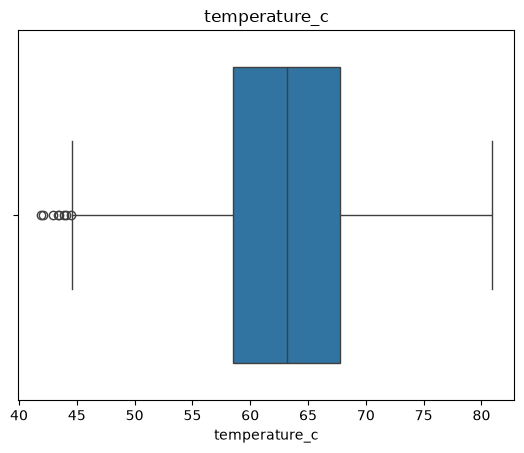


vibration_mm_s
Lower bound: 0.31499999999999995
Upper bound: 6.755
Potential outliers: 0

pressure_bar
Lower bound: 3.3900000000000023
Upper bound: 11.629999999999997
Potential outliers: 34


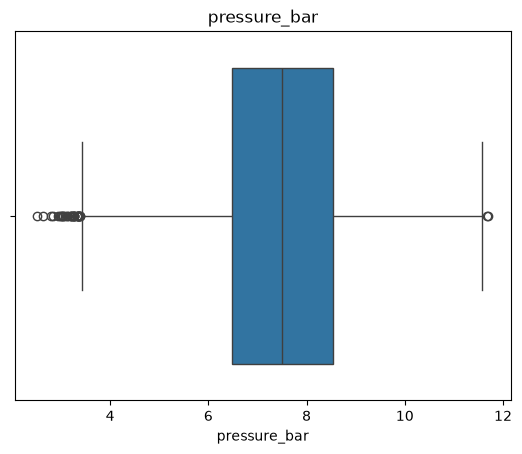


rotational_speed_rpm
Lower bound: 1421.0
Upper bound: 2253.0
Potential outliers: 357


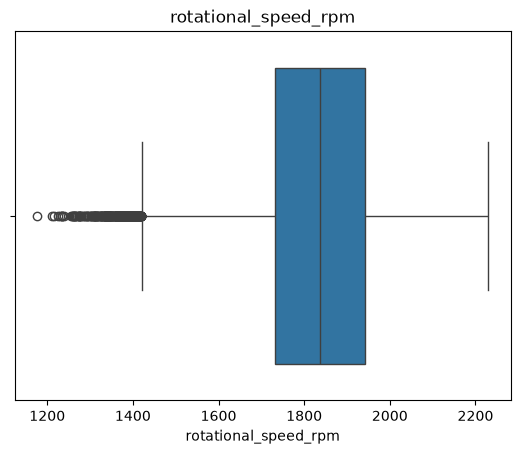


torque_nm
Lower bound: 123.60000000000001
Upper bound: 326.0
Potential outliers: 372


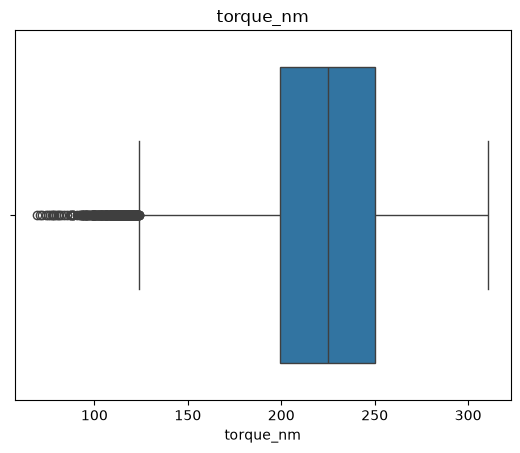


voltage_v
Lower bound: 373.5999999999999
Upper bound: 386.4000000000001
Potential outliers: 7863


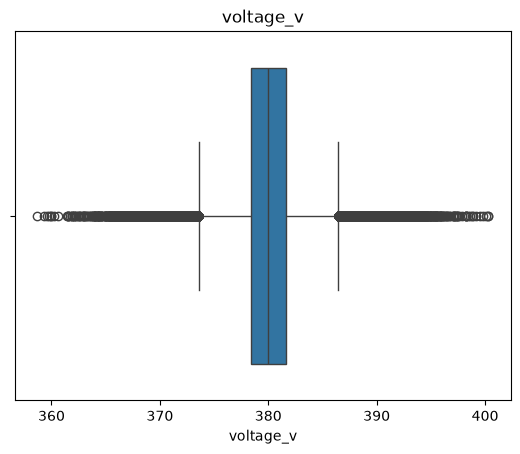


current_a
Lower bound: -146.84999999999997
Upper bound: 513.55
Potential outliers: 0

power_consumption_kw
Lower bound: -82.215
Upper bound: 287.425
Potential outliers: 0

humidity_percent
Lower bound: 17.80000000000001
Upper bound: 72.19999999999999
Potential outliers: 741


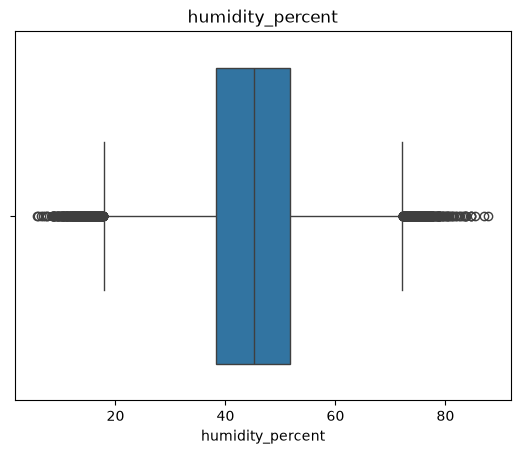


acoustic_level_db
Lower bound: 50.74999999999999
Upper bound: 77.55000000000001
Potential outliers: 18


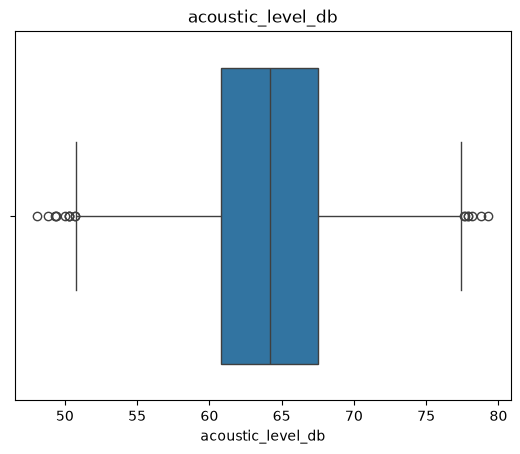


bearing_temperature_c
Lower bound: 48.9
Upper bound: 89.70000000000002
Potential outliers: 89


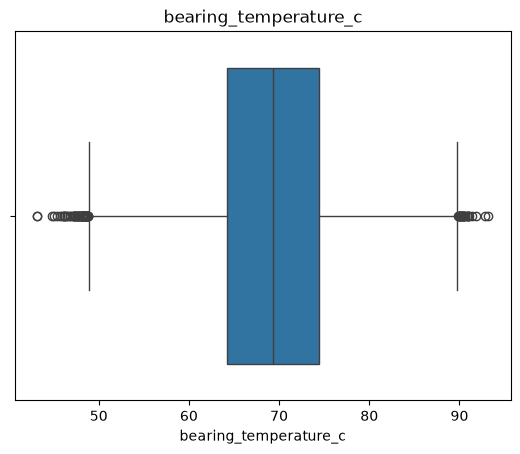


motor_temperature_c
Lower bound: 49.10000000000001
Upper bound: 91.49999999999999
Potential outliers: 86


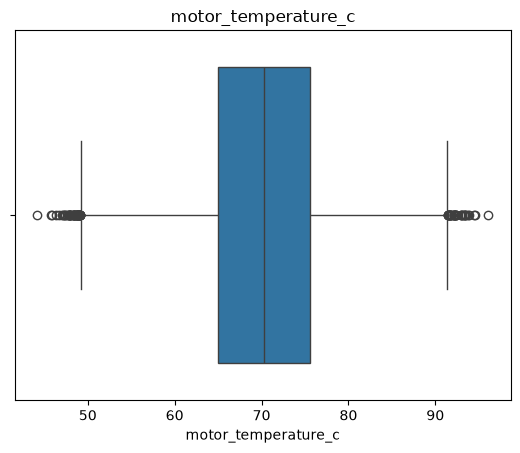


oil_temperature_c
Lower bound: 39.550000000000004
Upper bound: 76.75
Potential outliers: 19


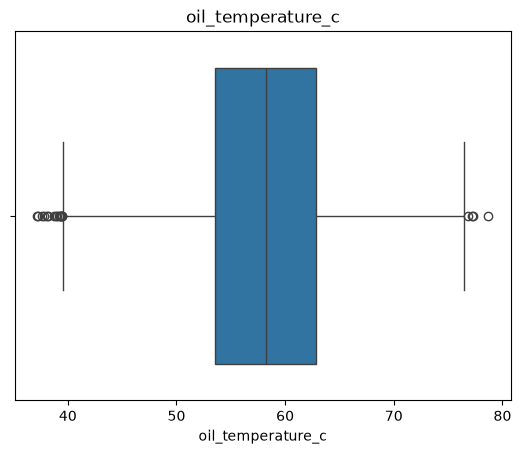


coolant_temperature_c
Lower bound: 25.800000000000008
Upper bound: 78.6
Potential outliers: 0

oil_pressure_bar
Lower bound: 2.6899999999999995
Upper bound: 9.33
Potential outliers: 33


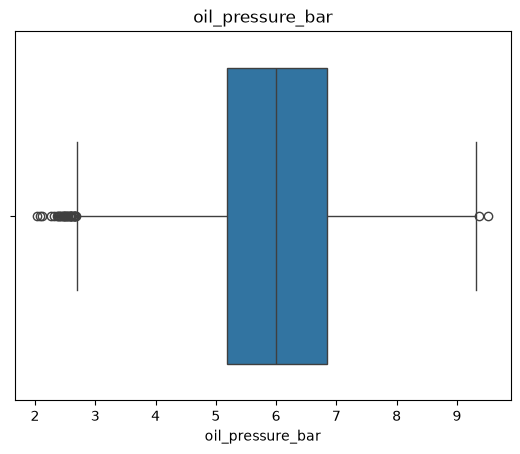


hydraulic_pressure_bar
Lower bound: 4.034999999999999
Upper bound: 13.995000000000001
Potential outliers: 31


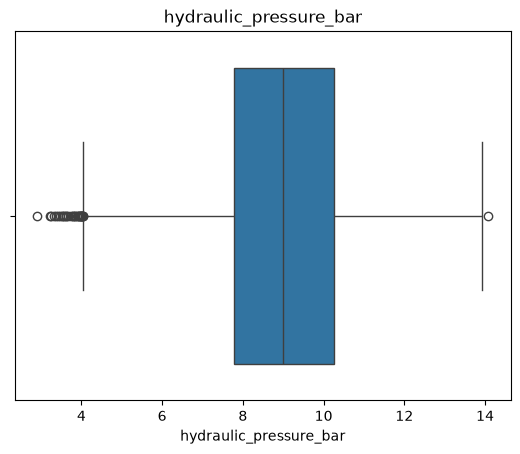


air_pressure_bar
Lower bound: 5.48
Upper bound: 6.52
Potential outliers: 867


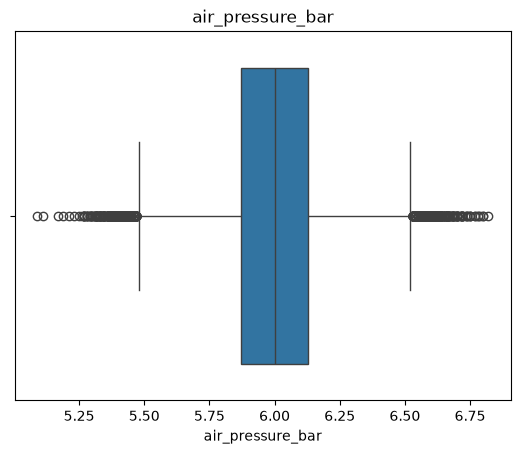

In [20]:
# Checking outliers in operating_conditions
operating_conditions = ['temperature_c','vibration_mm_s','pressure_bar','rotational_speed_rpm','torque_nm','voltage_v','current_a',
'power_consumption_kw','humidity_percent','acoustic_level_db','bearing_temperature_c','motor_temperature_c','oil_temperature_c',
'coolant_temperature_c','oil_pressure_bar','hydraulic_pressure_bar','air_pressure_bar']
for col in operating_conditions:
    Q1 = manufacturing[col].quantile(0.25)
    Q3 = manufacturing[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    outliers = ((manufacturing[col] < lower_fence) |(manufacturing[col] > upper_fence))
    
    print(f"\n{col}")
    print("Lower bound:", lower_fence)
    print("Upper bound:", upper_fence)
    print("Potential outliers:", outliers.sum())
    if outliers.sum() != 0 :
        sns.boxplot(x=manufacturing[col])
        plt.title(col)
        plt.show()

#### `Observation`
- **Outlier Investigation – `temperature_c`**
    - 8 potential outliers were identified using the IQR method, with values ranging from 41.9°C to 44.5°C, below the lower fence of 44.55°C. These values were retained because they do not appear inherently implausible as industrial temperature readings.
- **Outlier Investigation – `pressure_bar`** 
   - A total of 34 potential outliers were identified using the IQR method, with values below the lower fence of 3.39 bar or above the upper fence of 11.63 bar. Upon examining these values, most were found to be close to the respective statistical boundaries, ranging from 2.52 to 3.38 bar on the lower end and from 11.68 to 11.70 bar on the upper end. Given their proximity to the calculated fences, these values were assumed to stay within a normal operating range , so they were kept.
- **Outlier Investigation – `rotational_speed_rpm`**
   - A total of 357 potential outliers (0.36%) fell below the lower bound of 1,421 RPM. Given the strong positive linear correlation between rotational speed and load (r ≈ 0.97), these readings may reflect light-load operating conditions  , so they were kept.
- **Outlier Investigation – `torque_nm`**
   - A total of 372 potential outliers (0.37%) fell below the lower bound of 123.6 Nm. Given the very strong positive linear correlation between torque and load (r = 0.997), these readings likely reflect low-load operating conditions rather than sensor faults , so they were kept.
- **Outlier Investigation – `voltage_v`**
   - A total of 7,863 potential outliers (7.86%) were identified due to the narrow IQR range. Values ranged from 358.7 to 400.3 V and were retained, as no clear evidence of invalid measurements was found.

#### `Observation`
- **Outlier Investigation – `humidity_percent`**
   - 741 potential outliers (0.74%) were identified on both sides. Values ranged from 5.8% to 87.8% and were retained, as they fall within a potentially realistic humidity range.
- **Outlier Investigation – `acoustic_level_d`**
   - 18 potential outliers were identified using the IQR method, with values ranging from 48.1 to 79.3 dB, falling outside the bounds of 50.75–77.55 dB. These values were retained because they do not appear inherently implausible as industrial noise readings.
- **Outlier Investigation – `bearing_temperature_c`**
   - 89 potential outliers were identified using the IQR method, with values ranging from 43.2°C to 93.2°C, falling outside the bounds of 48.9–89.7°C. These values were retained because they do not appear inherently implausible as bearing temperature readings.
- **Outlier Investigation – `motor_temperature_c`**
   - 86 potential outliers were identified using the IQR method, with values ranging from 44.2°C to 96.1°C, falling outside the bounds of 49.1–91.5°C. These values were retained because they may be plausible for a running motor, depending on its operating conditions.
- **Outlier Investigation – `oil_temperature_c`**
   - 19 potential outliers were identified using the IQR method, with values falling outside the bounds of 39.55–76.75°C. These values were retained because no clear evidence of invalid measurements was found.
- **Outlier Investigation – `oil_pressure_bar`**
   - 33 potential outliers were identified using the IQR method, with values falling outside the bounds of 2.69–9.33 bar. Given the very strong correlation with pressure_bar (r ≈ 0.996), these readings may reflect similar operating conditions rather than errors. Therefore, they were retained.
- **Outlier Investigation – `hydraulic_pressure_bar`**
   - 31 potential outliers were identified using the IQR method, with values falling outside the bounds of 4.035–13.995 bar. These values were retained because they appear plausible, and no clear evidence of invalid measurements was found.


ambient_temperature_c
Lower bound: 11.200000000000003
Upper bound: 32.8
Potential outliers: 696


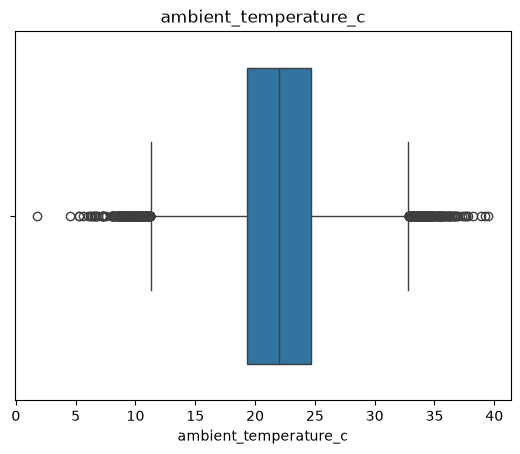


ambient_humidity_percent
Lower bound: 18.19999999999999
Upper bound: 71.80000000000001
Potential outliers: 747


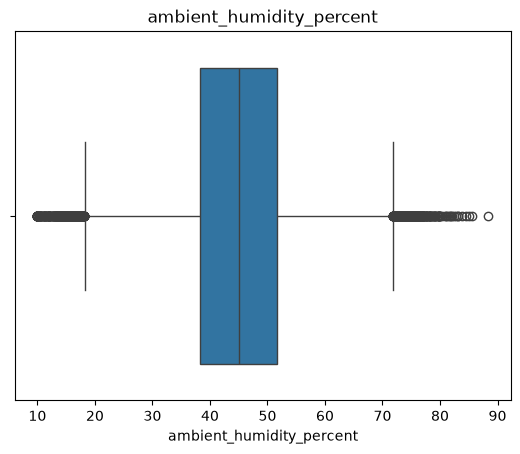


dust_level
Lower bound: -25.0
Upper bound: 115.0
Potential outliers: 0

air_quality_index
Lower bound: -45.5
Upper bound: 214.5
Potential outliers: 0

noise_level_db
Lower bound: 51.39999999999999
Upper bound: 78.60000000000001
Potential outliers: 609


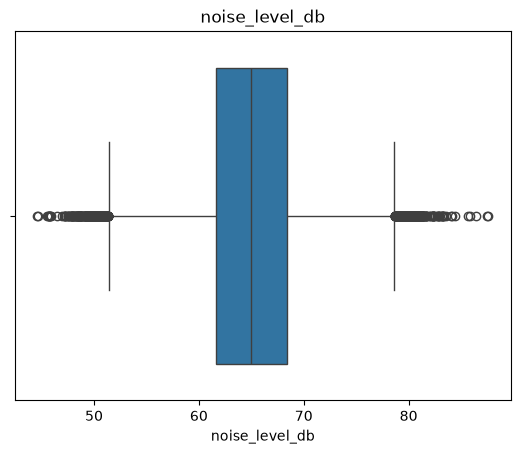

In [21]:
# Checking outliers in environmental_conditions
environmental_conditions = ['ambient_temperature_c','ambient_humidity_percent','dust_level','air_quality_index','noise_level_db']
for col in environmental_conditions:
    Q1 = manufacturing[col].quantile(0.25)
    Q3 = manufacturing[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    outliers = ((manufacturing[col] < lower_fence) |(manufacturing[col] > upper_fence))
    
    print(f"\n{col}")
    print("Lower bound:", lower_fence)
    print("Upper bound:", upper_fence)
    print("Potential outliers:", outliers.sum())
    if outliers.sum() != 0 :
        sns.boxplot(x=manufacturing[col])
        plt.title(col)
        plt.show()


operating_hours
Lower bound: -8664.9875
Upper bound: 46068.5125
Potential outliers: 0

idle_hours
Lower bound: -1.0
Upper bound: 3.0
Potential outliers: 0

production_cycles
Lower bound: -178867.375
Upper bound: 859729.625
Potential outliers: 870


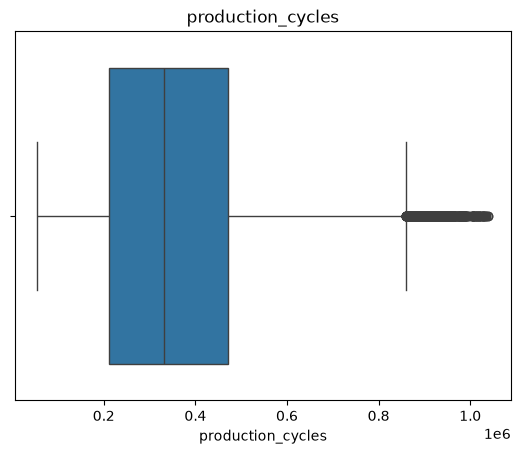


load_percentage
Lower bound: 29.499999999999993
Upper bound: 110.30000000000001
Potential outliers: 364


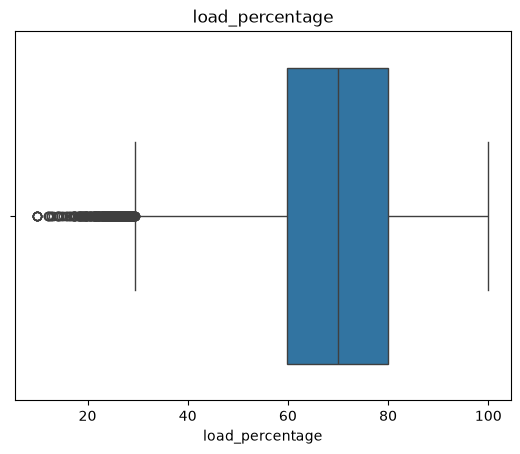


production_rate
Lower bound: 23.35000000000001
Upper bound: 115.74999999999999
Potential outliers: 449


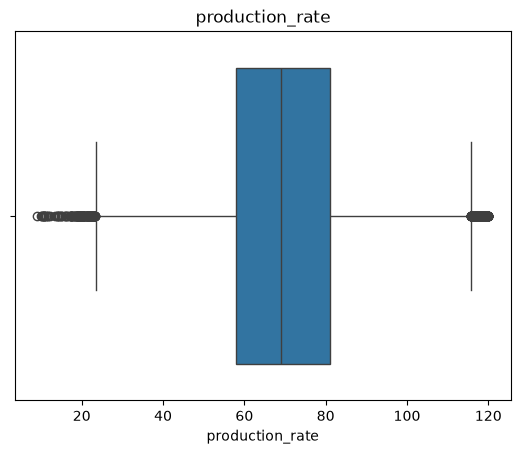


shift_hours
Lower bound: 8.0
Upper bound: 8.0
Potential outliers: 0

downtime_hours
Lower bound: -0.7999999999999999
Upper bound: 1.5999999999999999
Potential outliers: 4546


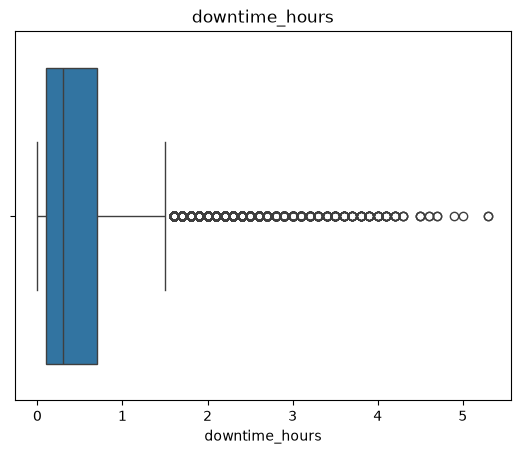


energy_consumption_kwh
Lower bound: -357.66125
Upper bound: 1203.36875
Potential outliers: 0


In [22]:
# Checking outliers in production_downtime
production_downtime = ['operating_hours','idle_hours','production_cycles','load_percentage','production_rate',
'shift_hours','downtime_hours','energy_consumption_kwh']
for col in production_downtime:
    Q1 = manufacturing[col].quantile(0.25)
    Q3 = manufacturing[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    outliers = ((manufacturing[col] < lower_fence) |(manufacturing[col] > upper_fence))
    
    print(f"\n{col}")
    print("Lower bound:", lower_fence)
    print("Upper bound:", upper_fence)
    print("Potential outliers:", outliers.sum())
    if outliers.sum() != 0 :
        sns.boxplot(x=manufacturing[col])
        plt.title(col)
        plt.show()

#### `Observation`
- **Outlier Investigation – `production_cycles`**
   - 870 potential outliers were identified using the IQR method, all above the upper fence of 859,729.625 cycles. These high values may reflect increased machine usage, as the column represents a cumulative production counter,The values were retained.
- **Outlier Investigation – `load_percentage`**
  - 364 potential outliers were identified below the lower fence of 29.5%, possibly reflecting lightly loaded machines.
- **Outlier Investigation – `production_rate`**
  - 449 potential outliers were identified using the IQR method, falling outside the statistical bounds of 23.35%–115.75%.  with some reaching. These values were retained as they may reflect actual operating performance.
- **Outlier Investigation – `downtime_hours`**
  - 4,547 potential outliers were identified , longer downtime events stand out statistically. However, these events are central to the project's analysis, so the values were retained for further investigation.


days_since_maintenance
Lower bound: -51.85000000000001
Upper bound: 178.95000000000002
Potential outliers: 0

maintenance_count
Lower bound: -10.5
Upper bound: 65.5
Potential outliers: 0

maintenance_cost
Lower bound: -2210.9675
Upper bound: 7402.7125
Potential outliers: 0

last_repair_duration_hours
Lower bound: -4.5
Upper bound: 13.100000000000001
Potential outliers: 4736


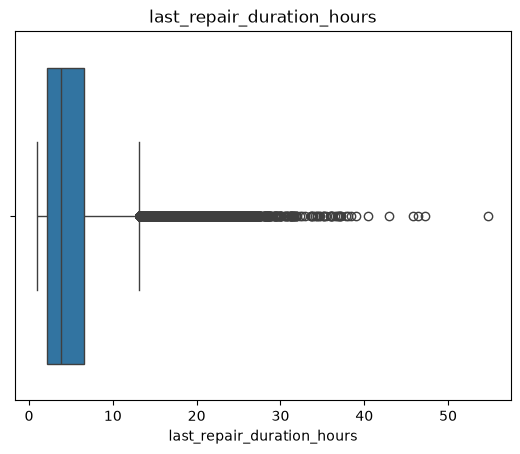


replacement_parts_count
Lower bound: -6.5
Upper bound: 13.5
Potential outliers: 0

technician_experience_years
Lower bound: -12.0
Upper bound: 36.0
Potential outliers: 0

previous_failure_count
Lower bound: -4.0
Upper bound: 12.0
Potential outliers: 580


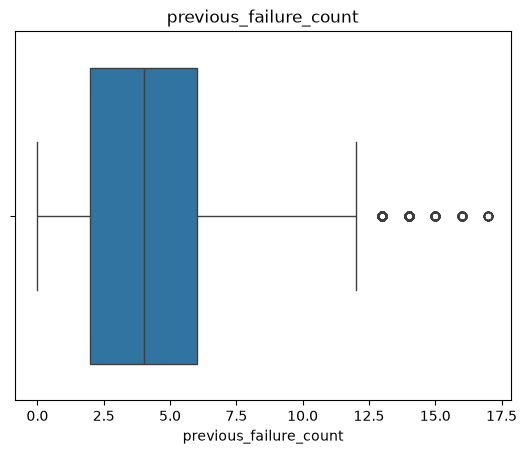


days_since_previous_failure
Lower bound: -149.24999999999997
Upper bound: 567.15
Potential outliers: 4840


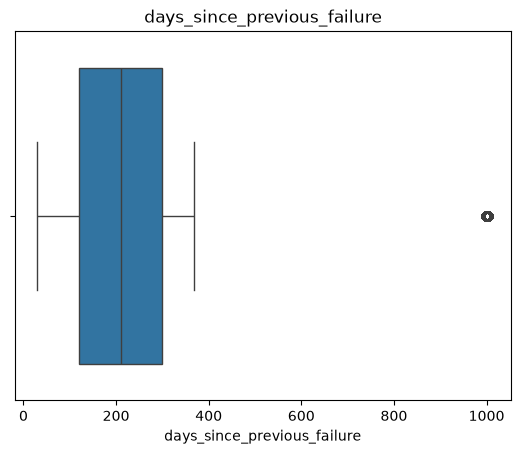


failure_frequency
Lower bound: -0.18
Upper bound: 1.1800000000000002
Potential outliers: 1740


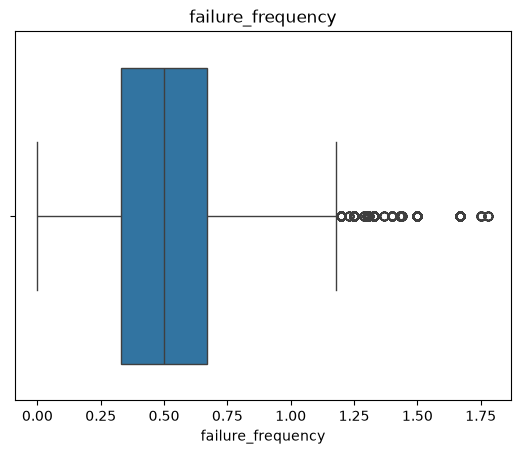

In [23]:
# Checking outliers in maintenance_failure 
maintenance_failure = ['days_since_maintenance','maintenance_count','maintenance_cost','last_repair_duration_hours',
'replacement_parts_count','technician_experience_years','previous_failure_count','days_since_previous_failure','failure_frequency']
for col in maintenance_failure:
    Q1 = manufacturing[col].quantile(0.25)
    Q3 = manufacturing[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    outliers = ((manufacturing[col] < lower_fence) |(manufacturing[col] > upper_fence))
    
    print(f"\n{col}")
    print("Lower bound:", lower_fence)
    print("Upper bound:", upper_fence)
    print("Potential outliers:", outliers.sum())
    if outliers.sum() != 0 :
        sns.boxplot(x=manufacturing[col])
        plt.title(col)
        plt.show()

In [24]:
# Extract date and time from the timestamp column
manufacturing['date_stamp'] = manufacturing['timestamp'].dt.date
manufacturing['time_stamp'] = manufacturing['timestamp'].dt.time

In [25]:
# Identify records where the machine_age differs from the calculated age 
calculated_age = (manufacturing["timestamp"].dt.year - manufacturing["installation_year"])
age_mismatch = manufacturing["machine_age"] != calculated_age
print("Age mismatches:", age_mismatch.sum())

Age mismatches: 0


In [26]:
# Data Consistency Check between failure_type  and machine_failure.
count = len(manufacturing[(manufacturing['machine_failure'] == 0) & (manufacturing['failure_type'] != 'No Failure')])
print('No machine failure with a specified failure type =' ,count)
count = len(manufacturing[(manufacturing['machine_failure'] != 0) & (manufacturing['failure_type'] == 'No Failure')])
print('Machine failure with a specified failure type =' ,count)
count = len(manufacturing[(manufacturing['machine_failure'] != 0) & (manufacturing['failure_type'] != 'No Failure')])
print('Zero downtime with a specified reason =' ,count)

No machine failure with a specified failure type = 0
Machine failure with a specified failure type = 0
Zero downtime with a specified reason = 1472


In [27]:
# Convert downtime hours to minutes
manufacturing['downtime_hours'] = manufacturing['downtime_hours'] * 60

In [28]:
# Convert idle_hours to minutes
manufacturing['idle_hours'] = manufacturing['idle_hours'] * 60

In [29]:
# Drop maintenance_priority 
manufacturing.drop(columns=['maintenance_priority'], inplace=True)

C:\Users\uo\AppData\Local\Temp\ipykernel_20472\3741782515.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  manufacturing.drop(columns=['maintenance_priority'], inplace=True)


In [30]:
# Drop factory_shift
manufacturing.drop(columns=['failure_probability'], inplace=True)

C:\Users\uo\AppData\Local\Temp\ipykernel_20472\1988133687.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  manufacturing.drop(columns=['failure_probability'], inplace=True)


In [31]:
# Drop factory_shift
manufacturing.drop(columns=['factory_shift'], inplace=True)

C:\Users\uo\AppData\Local\Temp\ipykernel_20472\2046532414.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  manufacturing.drop(columns=['factory_shift'], inplace=True)


In [32]:
# Rebuild factory_shift based on timestamp
hour = manufacturing['timestamp'].dt.hour
manufacturing['factory_shift'] = np.select([(hour >= 6) & (hour < 14),(hour >= 14) & (hour < 22)],
                                           ['Morning', 'Evening'],default='Night')

In [33]:
# Data Consistency Check between previous_failure_count  and days_since_previous_failure.
count = len(manufacturing[(manufacturing['previous_failure_count'] == 0) & (manufacturing['days_since_previous_failure'] != 0)])
print('No previous_failure_count but days since previous failure is not zero =' ,count)
count = len(manufacturing[(manufacturing['previous_failure_count'] != 0) & (manufacturing['days_since_previous_failure'] != 0)])
print('previous_failure_count with days_since_previous_failure =' ,count)

No previous_failure_count but days since previous failure is not zero = 4840
previous_failure_count with days_since_previous_failure = 95160


In [34]:
manufacturing.loc[manufacturing['previous_failure_count'] == 0,'days_since_previous_failure'] = 0

In [35]:
# Standardize column names by:Removing leading/trailing whitespace,Converting names to Title ,Replacing spaces and hyphens with underscores.
# snake_case 
manufacturing.columns = (manufacturing.columns.str.strip().str.replace(" " ,"_" , regex = False).str.replace("/" ,"_" , regex = False)
    .str.replace("-" ,"_" , regex = False).str.lower()) 
print(manufacturing.columns)

Index(['machine_id', 'monitoring_id', 'timestamp', 'factory_id',
       'production_line', 'machine_type', 'manufacturer', 'model',
       'installation_year', 'machine_age', 'machine_capacity',
       'machine_power_kw', 'machine_weight_kg', 'temperature_c',
       'vibration_mm_s', 'pressure_bar', 'rotational_speed_rpm', 'torque_nm',
       'voltage_v', 'current_a', 'power_consumption_kw', 'humidity_percent',
       'acoustic_level_db', 'bearing_temperature_c', 'motor_temperature_c',
       'oil_temperature_c', 'coolant_temperature_c', 'oil_pressure_bar',
       'hydraulic_pressure_bar', 'air_pressure_bar', 'operating_hours',
       'idle_hours', 'production_cycles', 'load_percentage', 'production_rate',
       'downtime_hours', 'shift_hours', 'energy_consumption_kwh',
       'ambient_temperature_c', 'ambient_humidity_percent', 'dust_level',
       'air_quality_index', 'noise_level_db', 'last_maintenance_date',
       'days_since_maintenance', 'maintenance_count', 'maintenance_cost',

In [36]:
#manufacturing.to_excel('cleaned_manufacturing.xlsx', index=False)

<div style="color: Green;  padding: 7px; border-radius: 5px; font-weight: bold; font-size: 25px;"> Data Warehouse Design </div>

## Grain : One row per machine monitoring record identified by monitoring_id.

In [37]:
# 1. Check if monitoring_id uniquely identifies each row (Primary Key check)
total_rows = len(manufacturing)
unique_monitoring_ids = manufacturing['monitoring_id'].nunique()
is_monitoring_unique = manufacturing['monitoring_id'].is_unique
print(f"Total Rows: {total_rows}")
print(f"Unique monitoring_id count: {unique_monitoring_ids}")
print(f"Does monitoring_id uniquely identify every row? {is_monitoring_unique}")

Total Rows: 100000
Unique monitoring_id count: 100000
Does monitoring_id uniquely identify every row? True


### Building Dim & Fact tables


### 1-dim_machine

In [18]:
dim_machine = manufacturing[["machine_id","machine_type","manufacturer","model","installation_year","machine_age","machine_capacity","machine_power_kw","machine_weight_kg"]].drop_duplicates().sort_values("machine_id").reset_index(drop=True)
dim_machine.insert(0, "machine_key", dim_machine.index + 1)
dim_machine

,machine_key,machine_id,machine_type,manufacturer,model,installation_year,machine_age,machine_capacity,machine_power_kw,machine_weight_kg
0,1,MCH-00001,Milling Machine,Fanuc,MOD-839,2022,4,404.7,144.1,2826.9
1,2,MCH-00002,Compressor,Bosch,MOD-516,2021,5,106.9,136.0,2870.7
2,3,MCH-00003,Lathe Machine,Caterpillar,MOD-694,2013,13,324.6,29.7,6545.0
3,4,MCH-00004,Conveyor System,Mitsubishi Electric,MOD-799,2023,3,498.2,61.6,1242.8
4,5,MCH-00005,Milling Machine,Mitsubishi Electric,MOD-320,2023,3,318.0,11.1,3917.4
...,...,...,...,...,...,...,...,...,...,...
4995,4996,MCH-04996,Milling Machine,Schneider Electric,MOD-619,2013,13,339.2,73.7,2403.5
4996,4997,MCH-04997,Compressor,Caterpillar,MOD-931,2012,14,472.3,146.0,1056.0
4997,4998,MCH-04998,Conveyor System,Bosch,MOD-405,2014,12,492.0,112.3,2710.8
4998,4999,MCH-04999,Hydraulic Press,Caterpillar,MOD-388,2015,11,476.1,187.2,6947.1


### 2-dim_shift

In [19]:
dim_shift = manufacturing[["factory_shift"]].drop_duplicates().sort_values("factory_shift").reset_index(drop=True)
dim_shift.insert(0, "shift_key", dim_shift.index + 1)
dim_shift

,shift_key,factory_shift
0,1,Evening
1,2,Morning
2,3,Night


### 3-dim_factory

In [20]:
dim_factory = manufacturing[["factory_id"]].drop_duplicates().sort_values("factory_id").reset_index(drop=True)
dim_factory.insert(0, "factory_key", dim_factory.index + 1)
dim_factory

,factory_key,factory_id
0,1,FAC-01
1,2,FAC-02
2,3,FAC-03
3,4,FAC-04
4,5,FAC-05
5,6,FAC-06
6,7,FAC-07
7,8,FAC-08
8,9,FAC-09
9,10,FAC-10


### 4-dim_date

In [21]:
manufacturing['date_stamp'] = pd.to_datetime(manufacturing['date_stamp'])
dates = manufacturing['date_stamp'].drop_duplicates().sort_values()
dim_date = pd.DataFrame({"full_date" : dates})
dim_date["date_key"] = dim_date["full_date"].dt.strftime("%Y%m%d").astype(int)
dim_date["year"] = dim_date["full_date"].dt.year
dim_date["quarter"] = dim_date["full_date"].dt.quarter
dim_date["month_name"] = dim_date["full_date"].dt.month_name()
dim_date["month"] = dim_date["full_date"].dt.month
dim_date["day"] = dim_date["full_date"].dt.day
dim_date["day_of_year"] = dim_date["full_date"].dt.dayofyear
dim_date["day_name"] = dim_date["full_date"].dt.day_name()
dim_date["week_of_year"] = dim_date["full_date"].dt.isocalendar().week.astype(int)
dim_date["is_weekend"] = dim_date["full_date"].dt.dayofweek >= 5
dim_date = dim_date[["date_key","full_date","year","quarter","month_name","month","day_name","day","day_of_year","week_of_year","is_weekend"]].reset_index(drop=True)
dim_date

,date_key,full_date,year,quarter,month_name,month,day_name,day,day_of_year,week_of_year,is_weekend
0,20260101,2026-01-01,2026,1,January,1,Thursday,1,1,1,False
1,20260102,2026-01-02,2026,1,January,1,Friday,2,2,1,False
2,20260103,2026-01-03,2026,1,January,1,Saturday,3,3,1,True
3,20260104,2026-01-04,2026,1,January,1,Sunday,4,4,1,True
4,20260105,2026-01-05,2026,1,January,1,Monday,5,5,2,False
...,...,...,...,...,...,...,...,...,...,...,...
61,20260303,2026-03-03,2026,1,March,3,Tuesday,3,62,10,False
62,20260304,2026-03-04,2026,1,March,3,Wednesday,4,63,10,False
63,20260305,2026-03-05,2026,1,March,3,Thursday,5,64,10,False
64,20260306,2026-03-06,2026,1,March,3,Friday,6,65,10,False


### 5-dim_production_line

In [22]:
dim_production_line = manufacturing[["production_line"]].drop_duplicates().sort_values("production_line").reset_index(drop=True)
dim_production_line.insert(0, "production_line_key", dim_production_line.index + 1)
dim_production_line

,production_line_key,production_line
0,1,LINE-01
1,2,LINE-02
2,3,LINE-03
3,4,LINE-04
4,5,LINE-05


### 6-dim_maintenance_type

In [23]:
dim_maintenance_type = manufacturing[["maintenance_type"]].drop_duplicates().sort_values("maintenance_type").reset_index(drop=True)
dim_maintenance_type.insert(0, "maintenance_type_key", dim_maintenance_type.index + 1)
dim_maintenance_type

,maintenance_type_key,maintenance_type
0,1,Corrective
1,2,Emergency
2,3,Predictive
3,4,Preventive
4,5,Routine


### 7-dim_failure_type

In [24]:
dim_failure_type = manufacturing[["failure_type"]].drop_duplicates().sort_values("failure_type").reset_index(drop=True)
dim_failure_type.insert(0, "failure_type_key", dim_failure_type.index + 1)
dim_failure_type

,failure_type_key,failure_type
0,1,Bearing Failure
1,2,Electrical Failure
2,3,Mechanical Failure
3,4,Motor Failure
4,5,No Failure
5,6,Overheating
6,7,Pressure Failure


### 8-fact_machine_montioring

In [25]:
fact_maintenance= manufacturing.copy().reset_index(drop=True)
fact_maintenance["date_key"] = pd.to_datetime(fact_maintenance["date_stamp"]).dt.strftime("%Y%m%d").astype(int)
fact_maintenance = (fact_maintenance
    .merge(dim_machine[["machine_id", "machine_key"]], on="machine_id", how="left")
    .merge(dim_shift[["shift_key", "factory_shift"]], on="factory_shift", how="left")
    .merge(dim_factory[["factory_key", "factory_id"]], on="factory_id", how="left")
    .merge(dim_production_line[["production_line_key", "production_line"]], on="production_line", how="left")
    .merge(dim_maintenance_type[["maintenance_type_key", "maintenance_type"]], on="maintenance_type", how="left")
    .merge(dim_failure_type[["failure_type_key", "failure_type"]], on="failure_type", how="left")
    .drop(columns=[
        "machine_id",
        "machine_type",
        "manufacturer",
        "model",
        "installation_year",
        "machine_age",
        "machine_capacity",
        "machine_power_kw",
        "machine_weight_kg",
        "factory_id",
        "production_line",
        "maintenance_type",
        "failure_type",
        "factory_shift",
        "date_stamp"
    ])
)
fact_maintenance.head()

,monitoring_id,timestamp,temperature_c,vibration_mm_s,pressure_bar,rotational_speed_rpm,torque_nm,voltage_v,current_a,power_consumption_kw,...,remaining_useful_life_hours,machine_failure,time_stamp,date_key,machine_key,shift_key,factory_key,production_line_key,maintenance_type_key,failure_type_key
0,MON-100000,2026-03-02 02:00:00,62.7,2.03,5.80,1742,201.1,377.7,259.3,144.18,...,14591,1,02:00:00,20260302,1,3,3,2,5,3
1,MON-100001,2026-03-02 05:00:00,66.5,2.46,5.95,1818,224.0,378.9,260.1,145.09,...,14363,0,05:00:00,20260302,1,3,3,2,4,5
2,MON-100002,2026-03-02 06:00:00,61.4,1.99,4.91,1662,179.8,381.1,255.7,143.46,...,14639,0,06:00:00,20260302,1,2,3,2,5,5
3,MON-100003,2026-03-02 12:00:00,64.3,1.88,6.21,1744,200.3,385.7,252.2,143.21,...,14459,0,12:00:00,20260302,1,2,3,2,2,5
4,MON-100004,2026-03-02 16:00:00,63.5,2.49,6.14,1778,212.7,383.5,254.3,143.57,...,14670,0,16:00:00,20260302,1,1,3,2,2,5


<div style="color: Green;  padding: 7px; border-radius: 5px; font-weight: bold; font-size: 25px;"> Connect with SQL Server </div>

In [ ]:
# use sqlalchemy to import data into SQL Server
from sqlalchemy import create_engine, text

SQL_SERVER = "localhost"
SQL_DATBASE = "ManufacturingDW"
SQL_DRIVER = "ODBC Driver 17 for SQL Server"
USE_TRUSTED_CONNECTION = True

try:
    conn_str = (
        f"mssql+pyodbc://@{SQL_SERVER}/{SQL_DATBASE}"
        f"?driver={SQL_DRIVER.replace(' ','+')}&trusted_connection=yes"
    )

    engine = create_engine(conn_str, fast_executemany=True)
    print("Conected to SQL Server")
except Exception as e:
    print(e)

with engine.connect() as conn:
    result = conn.execute(text("SELECT @@VERSION"))
    print(result.fetchone()[0])

In [ ]:
ddl_statements = [

	# Drop existing tables if they exist
	"DROP TABLE IF EXISTS dbo.fact_maintenance;",
	"DROP TABLE IF EXISTS dbo.dim_machine;",
	"DROP TABLE IF EXISTS dbo.dim_shift;",
	"DROP TABLE IF EXISTS dbo.dim_factory;",
	"DROP TABLE IF EXISTS dbo.dim_production_line;",
	"DROP TABLE IF EXISTS dbo.dim_date;",
	"DROP TABLE IF EXISTS dbo.dim_maintenance_type;",
	"DROP TABLE IF EXISTS dbo.dim_failure_type;",

	# Create Date dimension table
	"""
	CREATE TABLE dbo.dim_date (
		date_key INT PRIMARY KEY,
		full_date DATE NOT NULL,
		year SMALLINT NOT NULL,
		quarter TINYINT NOT NULL,
		month TINYINT NOT NULL,
		month_name VARCHAR(15) NOT NULL,
		day TINYINT NOT NULL,
		day_name VARCHAR(15) NOT NULL,
		day_of_year TINYINT NOT NULL,
		week_of_year TINYINT NOT NULL,
		is_weekend BIT NOT NULL
	);
	""",

	# Create Machine dimension table
	"""
	CREATE TABLE dbo.dim_machine (
		machine_key INT PRIMARY KEY,
		machine_id VARCHAR(12) NOT NULL UNIQUE,
		machine_type VARCHAR(50) NOT NULL,
		manufacturer VARCHAR(50) NOT NULL,
		model VARCHAR(50) NOT NULL,
		installation_year SMALLINT NOT NULL,
		machine_age SMALLINT NOT NULL,
		machine_capacity DECIMAL(10,2) NOT NULL,
		machine_power_kw DECIMAL(10,2) NOT NULL,
		machine_weight_kg DECIMAL(10,2) NOT NULL
		
	);
	""",

    #Create Shift dimension table
	"""
	CREATE TABLE dbo.dim_shift (
		shift_key INT PRIMARY KEY,
		factory_shift VARCHAR(20) NOT NULL
	);
	""",

    #Create Factory dimension table
	"""
	CREATE TABLE dbo.dim_factory (
		factory_key INT PRIMARY KEY,
		Factory_id VARCHAR(20) NOT NULL,
	);
	""",

    #Create Production Line dimension table
	"""
	CREATE TABLE dbo.dim_production_line (
		production_line_key INT PRIMARY KEY,
		production_line VARCHAR(20) NOT NULL
	);
	""",

	#Create Maintenance Type dimension table
	"""
		CREATE TABLE dbo.dim_maintenance_type (
			maintenance_type_key INT PRIMARY KEY,
			maintenance_type VARCHAR(20) NOT NULL
		);
		""",

	#Create Failure Type dimension table
	"""
		CREATE TABLE dbo.dim_failure_type (
			failure_type_key INT PRIMARY KEY,
			failure_type VARCHAR(20) NOT NULL
		);
		""",

	# Create Fact Maintenance table
	"""
	CREATE TABLE dbo.fact_maintenance (
	monitoring_id VARCHAR(15) PRIMARY KEY,
	timestamp DATETIME2(0) NOT NULL,
	temperature_c DECIMAL(10,2) NOT NULL,
	vibration_mm_s DECIMAL(10,2) NOT NULL,
	pressure_bar DECIMAL(10,2) NOT NULL,
	rotational_speed_rpm INT NOT NULL,
	torque_nm DECIMAL(10,2) NOT NULL,
	voltage_v DECIMAL(10,2) NOT NULL,
	current_a DECIMAL(10,2) NOT NULL,
	power_consumption_kw DECIMAL(10,2) NOT NULL,
	humidity_percent DECIMAL(10,2) NOT NULL,
	acoustic_level_db DECIMAL(10,2) NOT NULL,
	bearing_temperature_c DECIMAL(10,2) NOT NULL,
	motor_temperature_c DECIMAL(10,2) NOT NULL,
	oil_temperature_c DECIMAL(10,2) NOT NULL,
	coolant_temperature_c DECIMAL(10,2) NOT NULL,
	oil_pressure_bar DECIMAL(10,2) NOT NULL,
	hydraulic_pressure_bar DECIMAL(10,2) NOT NULL,
	air_pressure_bar DECIMAL(10,2) NOT NULL,
	operating_hours DECIMAL(12,2) NOT NULL,
	idle_hours DECIMAL(10,2) NOT NULL,
	production_cycles BIGINT NOT NULL,
	load_percentage DECIMAL(10,2) NOT NULL,
	production_rate DECIMAL(10,2) NOT NULL,
	downtime_hours DECIMAL(10,2) NOT NULL,
	shift_hours SMALLINT NOT NULL,
	energy_consumption_kwh DECIMAL(12,2) NOT NULL,
	ambient_temperature_c DECIMAL(10,2) NOT NULL,
	ambient_humidity_percent DECIMAL(10,2) NOT NULL,
	dust_level DECIMAL(10,2) NOT NULL,
	air_quality_index INT NOT NULL,
	noise_level_db DECIMAL(10,2) NOT NULL,
	last_maintenance_date DATE NOT NULL,
	days_since_maintenance DECIMAL(10,2) NOT NULL,
	maintenance_count INT NOT NULL,
	maintenance_cost DECIMAL(12,2) NOT NULL,
	last_repair_duration_hours DECIMAL(10,2) NOT NULL,
	replacement_parts_count INT NOT NULL,
	technician_experience_years INT NOT NULL,
	previous_failure_count INT NOT NULL,
	days_since_previous_failure DECIMAL(10,2) NOT NULL,
	failure_frequency DECIMAL(10,4) NOT NULL,
	bearing_health DECIMAL(6,2) NOT NULL,
	motor_health DECIMAL(6,2) NOT NULL,
	pump_health DECIMAL(6,2) NOT NULL,
	hydraulic_health DECIMAL(6,2) NOT NULL,
	electrical_health DECIMAL(6,2) NOT NULL,
	cooling_system_health DECIMAL(6,2) NOT NULL,
	temperature_anomaly_score DECIMAL(8,2) NOT NULL,
	vibration_anomaly_score DECIMAL(8,2) NOT NULL,
	pressure_anomaly_score DECIMAL(8,2) NOT NULL,
	electrical_anomaly_score DECIMAL(8,2) NOT NULL,
	energy_anomaly_score DECIMAL(8,2) NOT NULL,
	machine_health_score DECIMAL(6,2) NOT NULL,
	remaining_useful_life_hours INT NOT NULL,
	machine_failure TINYINT NOT NULL CHECK (machine_failure IN (0, 1)),
	time_stamp TIME(0) NOT NULL,
	date_key INT NOT NULL,
	machine_key INT NOT NULL,
	shift_key INT NOT NULL,
	factory_key INT NOT NULL,
	production_line_key INT NOT NULL,
	maintenance_type_key INT NOT NULL,
	failure_type_key INT NOT NULL,
	CONSTRAINT fk_fact_date             FOREIGN KEY (date_key)             REFERENCES dbo.dim_date(date_key),
    CONSTRAINT fk_fact_machine          FOREIGN KEY (machine_key)          REFERENCES dbo.dim_machine(machine_key),
    CONSTRAINT fk_fact_shift            FOREIGN KEY (shift_key)            REFERENCES dbo.dim_shift(shift_key),
    CONSTRAINT fk_fact_factory          FOREIGN KEY (factory_key)          REFERENCES dbo.dim_factory(factory_key),
    CONSTRAINT fk_fact_production_line  FOREIGN KEY (production_line_key)  REFERENCES dbo.dim_production_line(production_line_key),
    CONSTRAINT fk_fact_maintenance_type FOREIGN KEY (maintenance_type_key) REFERENCES dbo.dim_maintenance_type(maintenance_type_key),
    CONSTRAINT fk_fact_failure_type     FOREIGN KEY (failure_type_key)     REFERENCES dbo.dim_failure_type(failure_type_key)
);
	"""
]

with engine.begin() as conn:
	for stmt in ddl_statements:
		conn.execute(text(stmt))

print('tables created successfully')

### *Load Tables To SQL*

In [ ]:
# Load data into SQL Server tables in the correct order to maintain referential integrity
load_order = [
    ("dim_machine", dim_machine),
    ("dim_date", dim_date),
    ("dim_shift", dim_shift),
    ("dim_factory", dim_factory),
    ("dim_production_line", dim_production_line),
    ("dim_maintenance_type", dim_maintenance_type),
    ("dim_failure_type", dim_failure_type),
    ("fact_maintenance", fact_maintenance)
]

for table_name, df in load_order:
    df.to_sql(table_name, con=engine, schema="dbo", if_exists="append",
             index=False, chunksize=1000)
    print(f"Loaded {len(df)} rows --into--> dbo.{table_name}")

### *Create a New Dataframe for Modeling Steps*

In [ ]:
query = """
    SELECT 
        f.monitoring_id
        ,timestamp
        ,temperature_c
        ,vibration_mm_s
        ,pressure_bar
        ,rotational_speed_rpm
        ,torque_nm
        ,voltage_v
        ,current_a
        ,power_consumption_kw
        ,humidity_percent
        ,acoustic_level_db
        ,bearing_temperature_c
        ,motor_temperature_c
        ,oil_temperature_c
        ,coolant_temperature_c
        ,oil_pressure_bar
        ,hydraulic_pressure_bar
        ,air_pressure_bar
        ,operating_hours
        ,idle_hours
        ,production_cycles
        ,load_percentage
        ,production_rate
        ,downtime_hours
        ,shift_hours
        ,energy_consumption_kwh
        ,ambient_temperature_c
        ,ambient_humidity_percent
        ,dust_level
        ,air_quality_index
        ,noise_level_db
        ,last_maintenance_date
        ,days_since_maintenance
        ,maintenance_count
        ,maintenance_cost
        ,last_repair_duration_hours
        ,replacement_parts_count
        ,technician_experience_years
        ,previous_failure_count
        ,days_since_previous_failure
        ,failure_frequency
        ,bearing_health
        ,motor_health
        ,pump_health
        ,hydraulic_health
        ,electrical_health
        ,cooling_system_health
        ,temperature_anomaly_score
        ,vibration_anomaly_score
        ,pressure_anomaly_score
        ,electrical_anomaly_score
        ,energy_anomaly_score
        ,machine_health_score
        ,remaining_useful_life_hours
        ,machine_failure
        ,time_stamp
        ,d.full_date 
        ,d.month As month
        ,d.year As year
        ,d.quarter 
        ,d.month_name 
        ,d.day_name 
        ,d.day
        ,d.week_of_year 
        ,d.day_of_year 
        ,d.is_weekend
        ,m.machine_id
        ,m.machine_type
        ,m.manufacturer
        ,m.model
        ,m.installation_year
        ,m.machine_age
        ,m.machine_capacity
        ,m.machine_power_kw
        ,m.machine_weight_kg
        ,fa.Factory_id
        ,p.production_line
        ,s.factory_shift
        ,mt.maintenance_type
        ,ft.failure_type
    FROM dbo.fact_maintenance f
    JOIN dbo.dim_date d
        ON f.date_key = d.date_key
    JOIN dbo.dim_machine m
        ON f.machine_key = m.machine_key
    JOIN dbo.dim_factory fa
        ON f.factory_key = fa.factory_key
    JOIN dbo.dim_production_line p
        ON f.production_line_key = p.production_line_key
    JOIN dbo.dim_shift s
        ON f.shift_key = s.shift_key
    JOIN dbo.dim_maintenance_type mt
        ON f.maintenance_type_key = mt.maintenance_type_key
    JOIN dbo.dim_failure_type ft
        ON f.failure_type_key = ft.failure_type_key
"""

new_df = pd.read_sql(query, engine)
new_df.head(3)

In [ ]:
print('---the new data frame ---\n')
new_df.info()


---the new data frame---

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   monitoring_id                100000 non-null  str           
 1   timestamp                    100000 non-null  datetime64[us]
 2   temperature_c                100000 non-null  float64       
 3   vibration_mm_s               100000 non-null  float64       
 4   pressure_bar                 100000 non-null  float64       
 5   rotational_speed_rpm         100000 non-null  int64         
 6   torque_nm                    100000 non-null  float64       
 7   voltage_v                    100000 non-null  float64       
 8   current_a                    100000 non-null  float64       
 9   power_consumption_kw         100000 non-null  float64       
 10  humidity_percent             100000 non-null  float64       
 11  acoustic_lev

<div style="color: Green;  padding: 7px; border-radius: 5px; font-weight: bold; font-size: 25px;"> Exploratory Data Analysis </div>

In [30]:
# Count failures versus normal operation using the correct column
failure_counts = manufacturing['machine_failure'].value_counts()
print(failure_counts)

machine_failure
0    98528
1     1472
Name: count, dtype: int64


In [31]:
# Calculate the percentage of failures relative to total records
failure_percentage = (
    manufacturing['machine_failure'].value_counts(normalize=True) * 100
)
print(failure_percentage)

machine_failure
0    98.528
1     1.472
Name: proportion, dtype: float64


In [32]:
# Count the frequency of each failure type based on the failure_type column
failure_types_count = manufacturing['failure_type'].value_counts()
print(failure_types_count)

failure_type
No Failure            98528
Pressure Failure        265
Bearing Failure         255
Mechanical Failure      250
Motor Failure           242
Electrical Failure      238
Overheating             222
Name: count, dtype: int64


C:\Users\farou\AppData\Local\Temp\ipykernel_7068\1987139093.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


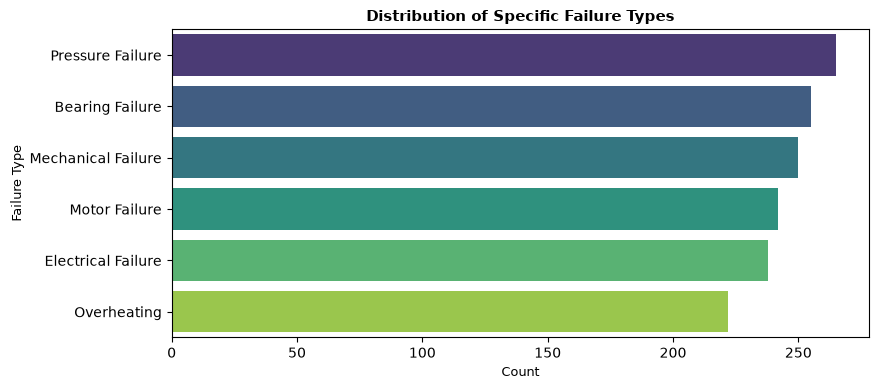

In [33]:
plt.figure(figsize=(9, 4))
sns.countplot(
    y='failure_type',
    data=manufacturing[manufacturing['failure_type'] != 'No Failure'],
    order=manufacturing['failure_type'].value_counts().index[1:],
    palette='viridis',
)
plt.title('Distribution of Specific Failure Types', fontsize=11, fontweight='bold')
plt.xlabel('Count', fontsize=9)
plt.ylabel('Failure Type', fontsize=9)
plt.show()

### Specific Failure Types Distribution
* **Purpose of the plot:** Identify which type of failure (mechanical, electrical, pressure, or heat) is the most frequent and has the greatest impact on production lines.
* **Practical benefit:** This analysis helps maintenance teams focus resources and spare parts on fixing the most damaging failure first (Prioritization).

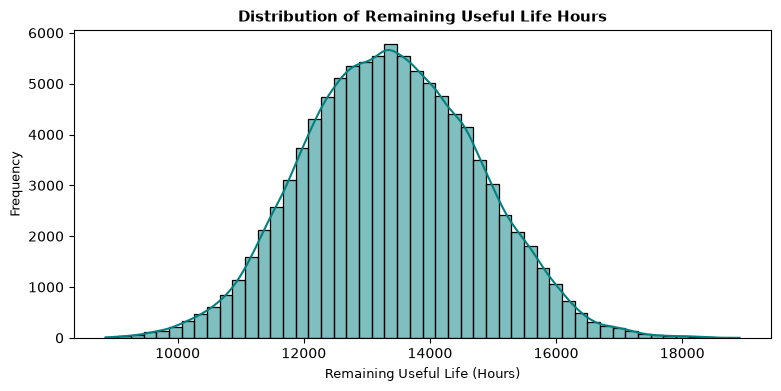

In [34]:
plt.figure(figsize=(9, 4))
sns.histplot(
    manufacturing['remaining_useful_life_hours'],
    bins=50,
    kde=True,
    color='teal',
)
plt.title(
    'Distribution of Remaining Useful Life Hours',
    fontsize=11,
    fontweight='bold',
)
plt.xlabel('Remaining Useful Life (Hours)', fontsize=9)
plt.ylabel('Frequency', fontsize=9)
plt.show()

### Remaining Useful Life Distribution
* **Purpose of the analysis:** Study the distribution of remaining hours in the machines' useful life across the records to determine how ready they are and how close they are to a critical stage.
* **Practical benefit:** Helps us set critical thresholds that warn us before a machine reaches complete failure.

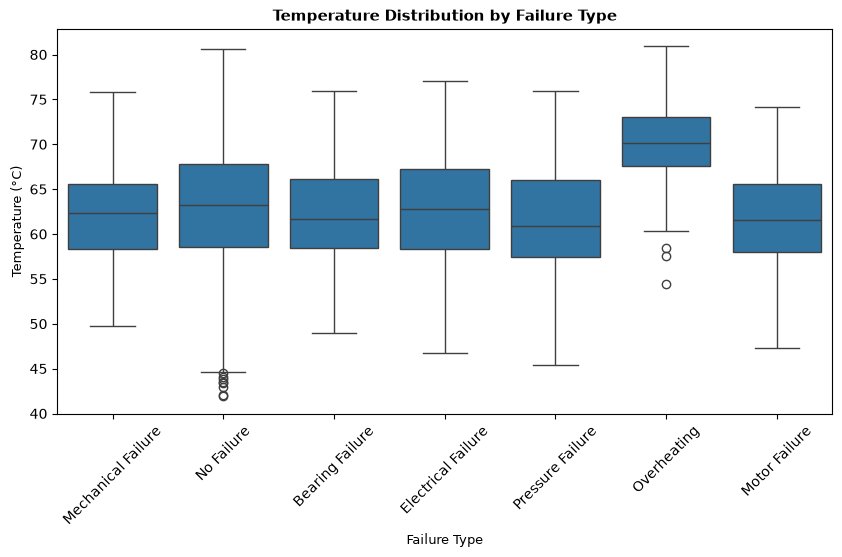

In [35]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='failure_type', y='temperature_c', data=manufacturing)
plt.title(
    'Temperature Distribution by Failure Type', fontsize=11, fontweight='bold'
)
plt.xlabel('Failure Type', fontsize=9)
plt.ylabel('Temperature (°C)', fontsize=9)
plt.xticks(rotation=45)
plt.show()

### Temperature vs. Failure Type
* **Purpose of the plot:** Compare the averages and ranges of temperatures associated with each failure type to determine whether excess heat is the main cause of a particular failure.
* **Practical benefit:** Helps us discover clear temperature thresholds that can be used as an early warning in predictive maintenance models.

In [36]:
print([col for col in manufacturing.columns if 'vibr' in col])

['vibration_mm_s', 'vibration_anomaly_score']


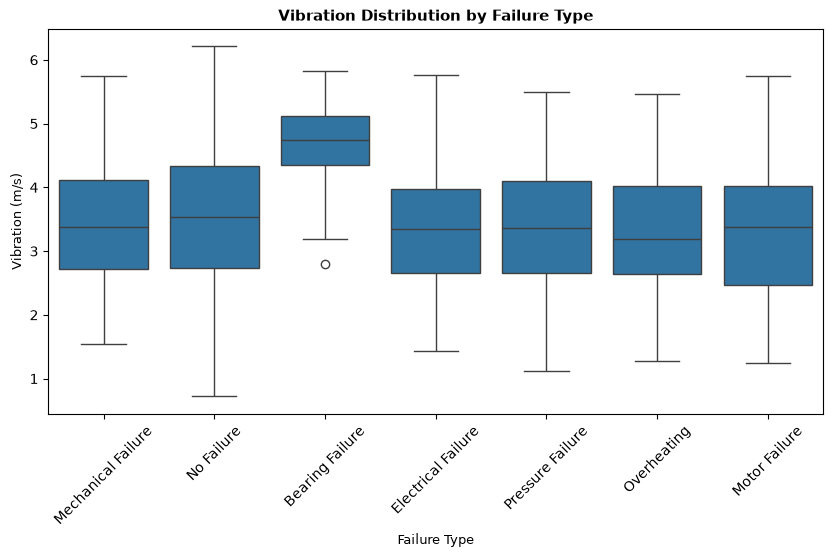

In [37]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='failure_type', y='vibration_mm_s', data=manufacturing)
plt.title('Vibration Distribution by Failure Type', fontsize=11, fontweight='bold')
plt.xlabel('Failure Type', fontsize=9)
plt.ylabel('Vibration (m/s)', fontsize=9)
plt.xticks(rotation=45)
plt.show()

### Vibration vs. Failure Type
* *Purpose of the plot:* Measure vibration levels and compare them across different failure types to understand how much mechanical vibration affects equipment damage.
* *Practical benefit:* Helps identify the critical vibration thresholds that distinguish mechanical failures from others, making it easier to detect early faults in rotating parts.


## Summary: Physical Factors and Their Effect on Failures
* **Overall goal:** Combine the results of the temperature (`temperature_c`) and vibration (`vibration_m_s`) studies with the failure types to understand the root cause of each failure.
* **Practical benefit:** Build an integrated predictive model based on multiple indicators (multi-sensor data) instead of relying on a single factor, which greatly improves maintenance prediction accuracy.
* **Conclusion and final recommendation:** 
  * The combination of high temperature and abnormal vibration is the main indicator of critical failures.
  * **Recommendation:** Use the thresholds discovered from the box plots as rules in the automated monitoring system.